In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Titanic-Dataset.csv to Titanic-Dataset.csv


In [4]:
df = pd.read_csv("Titanic-Dataset.csv")

print(df)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [5]:
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [6]:
print(df.tail())

     PassengerId  Survived  Pclass                                      Name  \
886          887         0       2                     Montvila, Rev. Juozas   
887          888         1       1              Graham, Miss. Margaret Edith   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
886    male  27.0      0      0      211536  13.00   NaN        S  
887  female  19.0      0      0      112053  30.00   B42        S  
888  female   NaN      1      2  W./C. 6607  23.45   NaN        S  
889    male  26.0      0      0      111369  30.00  C148        C  
890    male  32.0      0      0      370376   7.75   NaN        Q  


In [8]:
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [9]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [11]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

Categorical Columns:
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


In [12]:
print(df.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [13]:
print(df.describe(include="object"))

                       Name   Sex  Ticket Cabin Embarked
count                   891   891     891   204      889
unique                  891     2     681   147        3
top     Dooley, Mr. Patrick  male  347082    G6        S
freq                      1   577       7     4      644


In [14]:
print("Age Mean:", df["Age"].mean())

print("Age Median:", df["Age"].median())

print("Fare Mean:", df["Fare"].mean())

print("Sex Mode:", df["Sex"].mode()[0])

Age Mean: 29.69911764705882
Age Median: 28.0
Fare Mean: 32.204207968574636
Sex Mode: male


In [15]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [16]:
missing_count = df.isnull().sum()

missing_percentage = (
    missing_count / len(df)
) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

print(missing_table)

             Missing Count  Missing Percentage
PassengerId              0            0.000000
Survived                 0            0.000000
Pclass                   0            0.000000
Name                     0            0.000000
Sex                      0            0.000000
Age                    177           19.865320
SibSp                    0            0.000000
Parch                    0            0.000000
Ticket                   0            0.000000
Fare                     0            0.000000
Cabin                  687           77.104377
Embarked                 2            0.224467


In [17]:
df_clean = df.copy()

In [18]:
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

In [19]:
df_clean["Fare"] = df_clean["Fare"].fillna(
    df_clean["Fare"].median()
)

In [20]:
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

In [21]:
df_clean = df_clean.drop(columns=["Cabin"])

In [22]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [23]:
print("Duplicate Rows:", df_clean.duplicated().sum())

Duplicate Rows: 0


In [24]:
df_clean = df_clean.drop_duplicates()

In [25]:
print("Duplicates After Cleaning:",
      df_clean.duplicated().sum())

Duplicates After Cleaning: 0


In [26]:
for col in df_clean.select_dtypes(
    include=["object"]
).columns:

    df_clean[col] = df_clean[col].str.strip()

In [27]:
print("Sex Values:")
print(df_clean["Sex"].unique())

print("Embarked Values:")
print(df_clean["Embarked"].unique())

Sex Values:
['male' 'female']
Embarked Values:
['S' 'C' 'Q']


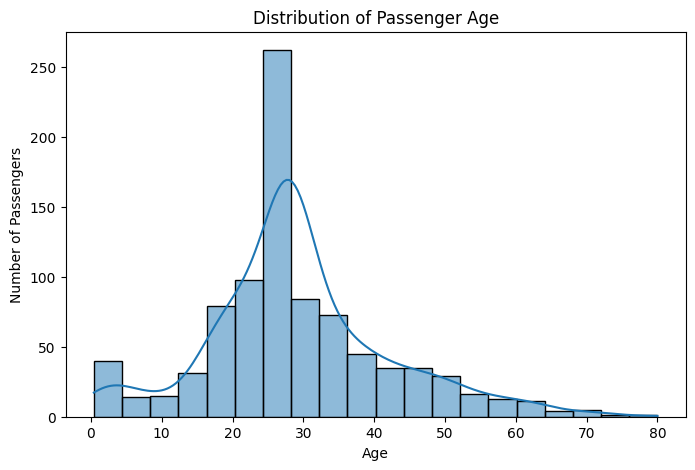

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df_clean["Age"],
    bins=20,
    kde=True
)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

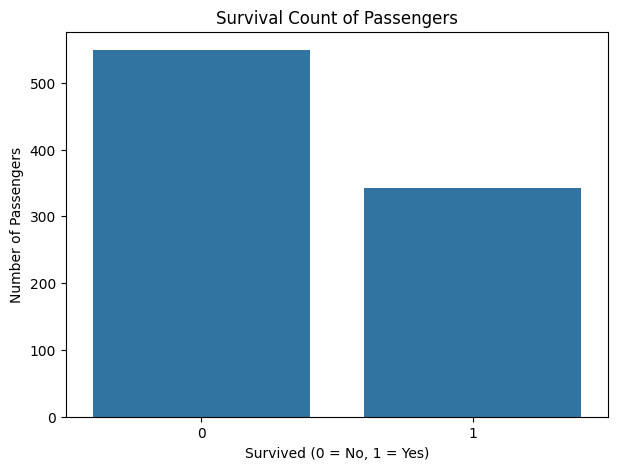

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Survived"
)

plt.title("Survival Count of Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

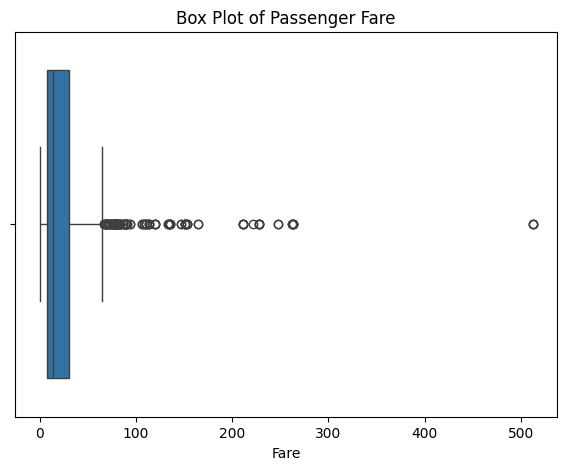

In [30]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x=df_clean["Fare"]
)

plt.title("Box Plot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

In [31]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

print(df_encoded.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                             Heikkinen, Miss. Laina  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                           Allen, Mr. William Henry  35.0      0      0   

             Ticket     Fare  Sex_male  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500         1           0           1  
1          PC 17599  71.2833         0           0           0  
2  STON/O2. 3101282   7.9250         0           0           1  
3            113803  53.1000         0           0           1  
4

In [32]:
df_encoded = df_encoded.drop(
    columns=["PassengerId", "Name", "Ticket"]
)

print(df_encoded.head())

   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500         1           0   
1         1       1  38.0      1      0  71.2833         0           0   
2         1       3  26.0      0      0   7.9250         0           0   
3         1       1  35.0      1      0  53.1000         0           0   
4         0       3  35.0      0      0   8.0500         1           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  


In [33]:
scaler = StandardScaler()

scale_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

df_encoded[scale_columns] = scaler.fit_transform(
    df_encoded[scale_columns]
)

print(df_encoded.head())

   Survived  Pclass       Age     SibSp     Parch      Fare  Sex_male  \
0         0       3 -0.565736  0.432793 -0.473674 -0.502445         1   
1         1       1  0.663861  0.432793 -0.473674  0.786845         0   
2         1       3 -0.258337 -0.474545 -0.473674 -0.488854         0   
3         1       1  0.433312  0.432793 -0.473674  0.420730         0   
4         0       3  0.433312 -0.474545 -0.473674 -0.486337         1   

   Embarked_Q  Embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


In [34]:
print("Final Dataset Shape:")
print(df_encoded.shape)

print("\nMissing Values:")
print(df_encoded.isnull().sum())

print("\nDuplicate Rows:")
print(df_encoded.duplicated().sum())

print("\nFinal Columns:")
print(df_encoded.columns)

print("\nFinal Dataset:")
print(df_encoded.head())

Final Dataset Shape:
(891, 9)

Missing Values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Duplicate Rows:
116

Final Columns:
Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male',
       'Embarked_Q', 'Embarked_S'],
      dtype='object')

Final Dataset:
   Survived  Pclass       Age     SibSp     Parch      Fare  Sex_male  \
0         0       3 -0.565736  0.432793 -0.473674 -0.502445         1   
1         1       1  0.663861  0.432793 -0.473674  0.786845         0   
2         1       3 -0.258337 -0.474545 -0.473674 -0.488854         0   
3         1       1  0.433312  0.432793 -0.473674  0.420730         0   
4         0       3  0.433312 -0.474545 -0.473674 -0.486337         1   

   Embarked_Q  Embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


In [35]:
df_encoded.to_csv(
    "Titanic_Prepared.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [36]:
from google.colab import files

files.download("Titanic_Prepared.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>